UTS Studi Kasus – Analisis Warna Daun (RGB)
Topik: Clustering dengan Metode Unsupervised Learning

Deskripsi Tugas
Tugas kali ini adalah melakukan studi kasus analisis data dan clustering menggunakan
metode unsupervised learning pada dataset warna daun (RGB). Mahasiswa diminta
untuk menerapkan tahapan data preprocessing, clustering, dan approximate nearest
neighbor untuk menemukan pola serta kelompok warna daun yang memiliki kemiripan.

# 1. Preprocessing data

1. Import Data

In [ ]:
import pandas as pd

# Baca dataset Excel dan ambil kolom R, G, B
df = pd.read_excel('/content/drive/MyDrive/Dataset Mesin/Data RGB Warna Daun.xlsx', skiprows=3)
df = df[['R', 'G', 'B']]

# Pastikan semua kolom numerik
df = df.apply(pd.to_numeric, errors='coerce')

# Penjelasan singkat dataset
jumlah_sampel = df.shape[0]
jumlah_fitur = df.shape[1]
tipe_data = df.dtypes

print("=== PENJELASAN SINGKAT DATASET ===")
print(f"Jumlah sampel  : {jumlah_sampel}")
print(f"Jumlah fitur   : {jumlah_fitur}")
print("Tipe data tiap fitur:")
print(tipe_data)


=== PENJELASAN SINGKAT DATASET ===
Jumlah sampel  : 1389
Jumlah fitur   : 3
Tipe data tiap fitur:
R      int64
G    float64
B    float64
dtype: object


2. Tangani missing values (jika ada menggunakan
imputasi, mean/median/modus sesuai jenis data)


In [ ]:
import pandas as pd

# mengambil kolom RGB
df = df[['R', 'G', 'B']]

# Konversi ke numerik
df = df.apply(pd.to_numeric, errors='coerce')

#Cek jumlah missing values sebelum imputasi
print("Missing values sebelum imputasi:")
print(df.isnull().sum())

#Tangani missing values menggunakan MEAN
df = df.fillna(df.mean(numeric_only=True))

# Cek kembali setelah imputasi
print("\nMissing values setelah imputasi:")
print(df.isnull().sum())

# Menampilkan beberapa data awal
print("data setelah imputasi:")
print(df.head())


Missing values sebelum imputasi:
R    0
G    0
B    0
dtype: int64

Missing values setelah imputasi:
R    0
G    0
B    0
dtype: int64
data setelah imputasi:
     R      G       B
0  151  149.0  106.40
1  151  149.0  109.78
2  151  149.0  106.40
3  151  149.0  130.06
4  151  151.4  106.40


3. Normalisasi / Standarisasi

In [ ]:
from sklearn.preprocessing import MinMaxScaler
import pandas as pd

# Misal df hasil dari langkah sebelumnya
scaler = MinMaxScaler()
df_normalized = pd.DataFrame(scaler.fit_transform(df), columns=['R', 'G', 'B'])

print("hasil normalisasi (Min–Max):")
print(df_normalized.head())

print("\nRentang nilai tiap kolom setelah normalisasi:")
print(df_normalized.describe())


hasil normalisasi (Min–Max):
          R         G         B
0  0.530612  0.421053  0.423077
1  0.530612  0.421053  0.461538
2  0.530612  0.421053  0.423077
3  0.530612  0.421053  0.692308
4  0.530612  0.473684  0.423077

Rentang nilai tiap kolom setelah normalisasi:
                 R            G            B
count  1389.000000  1389.000000  1389.000000
mean      0.466846     0.448410     0.522028
std       0.145743     0.146831     0.178633
min       0.000000     0.000000     0.000000
25%       0.387755     0.421053     0.384615
50%       0.448980     0.473684     0.500000
75%       0.530612     0.526316     0.692308
max       1.000000     1.000000     1.000000


4. Pembuatan Fitur Baru hasil kombinasi fitur lama,  
misalnya: - ExG = 2*G - R - B - Greenness = (G - R) / (R + G + B)

In [ ]:
import pandas as pd
df_normalized['ExG'] = 2 * df_normalized['G'] - df_normalized['R'] - df_normalized['B']
df_normalized['Greenness'] = (df_normalized['G'] - df_normalized['R']) / (df_normalized['R'] + df_normalized['G'] + df_normalized['B'])

# hasil
print("Data setelah penambahan fitur baru:")
print(df_normalized.head())


Data setelah penambahan fitur baru:
          R         G         B       ExG  Greenness
0  0.530612  0.421053  0.423077 -0.111584  -0.079695
1  0.530612  0.421053  0.461538 -0.150045  -0.077526
2  0.530612  0.421053  0.423077 -0.111584  -0.079695
3  0.530612  0.421053  0.692308 -0.380815  -0.066643
4  0.530612  0.473684  0.423077 -0.006321  -0.039883


# 2. Clustering

*   Terapkan K-Means dan DBSCAN (Untuk No. Absen Ganjil 1, 3, 5, dst)
*   Terapkan K-Means dan HDBSCAN (Untuk No. Absen Genap 2, 4, 6,
dst)
*  Bandingkan hasil clustering menggunakan:
1.   Silhouette Score
2.   Davies–Bouldin Index

In [ ]:
!pip install kneed

Jumlah cluster optimal menurut metode elbow: 4


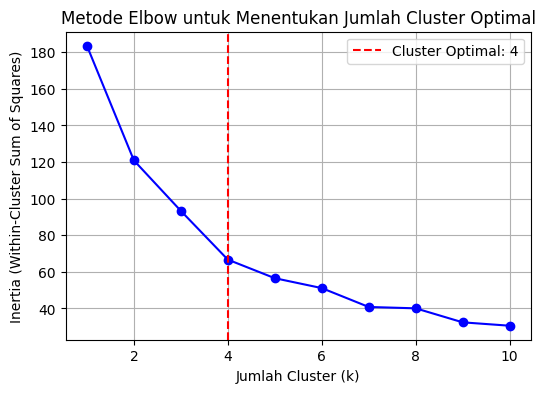

In [ ]:
# ============================================
# METODE ELBOW UNTUK MENENTUKAN JUMLAH CLUSTER OPTIMAL
# ============================================
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from kneed import KneeLocator  # Library untuk mendeteksi titik elbow

# Ambil data hasil preprocessing
df_clean = df_normalized.copy()

# Fitur yang digunakan
data = df_clean[['R', 'G', 'B', 'ExG', 'Greenness']]

# Tangani nilai kosong (jika ada)
data = data.fillna(data.mean(numeric_only=True))

# ============================================================
# 🔹 ELBOW METHOD
# ============================================================
inertia_values = []
cluster_range = range(1, 11)  # Uji jumlah cluster dari 1 sampai 10

for k in cluster_range:
    kmeans_temp = KMeans(n_clusters=k, random_state=42)
    kmeans_temp.fit(data)
    inertia_values.append(kmeans_temp.inertia_)

# ============================================================
# 🔹 DETEKSI CLUSTER OPTIMAL DENGAN KNEELOCATOR
# ============================================================
knee = KneeLocator(cluster_range, inertia_values, curve='convex', direction='decreasing')
optimal_k = knee.knee

print(f"Jumlah cluster optimal menurut metode elbow: {optimal_k}")

# ============================================================
# 🔹 VISUALISASI
# ============================================================
plt.figure(figsize=(6, 4))
plt.plot(cluster_range, inertia_values, marker='o', color='b')
if optimal_k is not None:
    plt.axvline(x=optimal_k, color='r', linestyle='--', label=f'Cluster Optimal: {optimal_k}')
plt.title('Metode Elbow untuk Menentukan Jumlah Cluster Optimal')
plt.xlabel('Jumlah Cluster (k)')
plt.ylabel('Inertia (Within-Cluster Sum of Squares)')
plt.grid(True)
plt.legend()
plt.show()


=== HASIL CLUSTERING: K-MEANS ===
Jumlah Cluster: 4
Silhouette Score: 0.4325
Davies–Bouldin Index: 0.9900


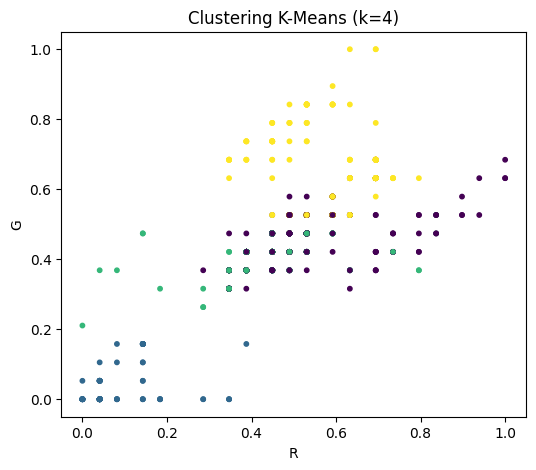

In [ ]:
# ============================================
# K-MEANS CLUSTERING
# ============================================
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Ambil data hasil preprocessing
df_clean = df_normalized.copy()

# Pilih fitur yang digunakan
data = df_clean[['R', 'G', 'B', 'ExG', 'Greenness']].fillna(df_clean.mean(numeric_only=True))

# Gunakan jumlah cluster hasil dari Elbow Method (misal: 3)
k_optimal = 4
kmeans = KMeans(n_clusters=k_optimal, random_state=42)
kmeans_labels = kmeans.fit_predict(data)

# Evaluasi hasil clustering
sil_score = silhouette_score(data, kmeans_labels)
dbi_score = davies_bouldin_score(data, kmeans_labels)

print("=== HASIL CLUSTERING: K-MEANS ===")
print(f"Jumlah Cluster: {k_optimal}")
print(f"Silhouette Score: {sil_score:.4f}")
print(f"Davies–Bouldin Index: {dbi_score:.4f}")

# Visualisasi hasil clustering (R vs G)
plt.figure(figsize=(6,5))
plt.scatter(data['R'], data['G'], c=kmeans_labels, cmap='viridis', s=10)
plt.title(f'Clustering K-Means (k={k_optimal})')
plt.xlabel('R')
plt.ylabel('G')
plt.show()


Cluster yang terbentuk oleh HDBSCAN: [-1, 0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28]

=== HASIL CLUSTERING: HDBSCAN ===
Silhouette Score: None
Davies–Bouldin Index: None


/usr/local/lib/python3.12/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/sklearn/utils/deprecation.py:151: FutureWarning: 'force_all_finite' was renamed to 'ensure_all_finite' in 1.6 and will be removed in 1.8.
  warnings.warn(


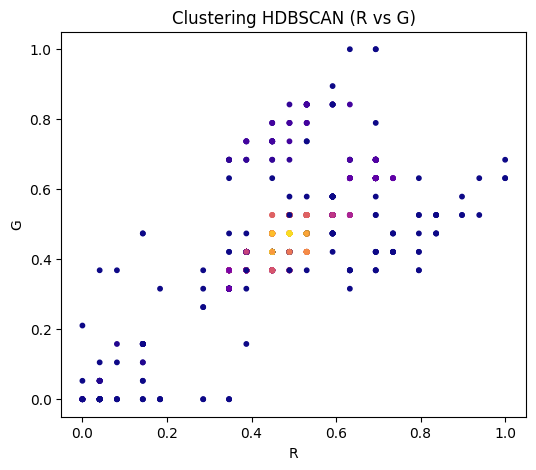

In [ ]:
# ============================================
# HDBSCAN CLUSTERING
# ============================================
import pandas as pd
import matplotlib.pyplot as plt
import hdbscan
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Ambil data hasil preprocessing
df_clean = df_normalized.copy()

# Pilih fitur yang digunakan
data = df_clean[['R', 'G', 'B', 'ExG', 'Greenness']].fillna(df_clean.mean(numeric_only=True))

# Buat model HDBSCAN
clusterer = hdbscan.HDBSCAN(
    min_cluster_size=20,   # ukuran minimum cluster
    min_samples=10,        # ketatkan batas agar cluster lebih stabil
    cluster_selection_epsilon=0.05,
    gen_min_span_tree=True
)

# Latih dan prediksi cluster
hdbscan_labels = clusterer.fit_predict(data)

# Konversi ke tipe int biasa (biar gak muncul np.int64)
hdbscan_labels = [int(i) for i in hdbscan_labels]

# Cek cluster unik
unique_clusters = sorted(set(hdbscan_labels))
print("Cluster yang terbentuk oleh HDBSCAN:", unique_clusters)

# Evaluasi hanya jika ada lebih dari 1 cluster valid
if len(set(hdbscan_labels)) > 1 and -1 not in set(hdbscan_labels):
    sil_hdbscan = silhouette_score(data, hdbscan_labels)
    dbi_hdbscan = davies_bouldin_score(data, hdbscan_labels)
else:
    sil_hdbscan = None
    dbi_hdbscan = None

print("\n=== HASIL CLUSTERING: HDBSCAN ===")
print(f"Silhouette Score: {sil_hdbscan}")
print(f"Davies–Bouldin Index: {dbi_hdbscan}")

# Visualisasi hasil HDBSCAN (R vs G)
plt.figure(figsize=(6,5))
plt.scatter(data['R'], data['G'], c=hdbscan_labels, cmap='plasma', s=10)
plt.title('Clustering HDBSCAN (R vs G)')
plt.xlabel('R')
plt.ylabel('G')
plt.show()


# Approximate Nearest Neighbor (ANN)

Gunakan Annoy untuk mencari tetangga terdekat dari beberapa query
points hasil clustering Tampilkan output berupa:
*   Index query point
*   Daftar tetangga terdekat yang ditemukan
*   Nilai jarak kemiripan

In [ ]:
!pip install annoy


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 647.5/647.5 kB 12.0 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for annoy: filename=annoy-1.17.3-cp312-cp312-linux_x86_64.whl size=551521 sha256=a4f0f4f9f62a2caaddf3f09c7d41150d896abd0fcd93a893d6bb2f6854800965
  Stored in directory: /root/.cache/pip/wheels/db/b9/53/a3b2d1fe1743abadddec6aa541294b24fdbc39d7800bc57311
Successfully built annoy


In [ ]:
from annoy import AnnoyIndex
import random
from sklearn.preprocessing import StandardScaler

# ===================================
# 1. Ambil data dan scaling
# ===================================
data = df_clean[['R', 'G', 'B', 'ExG', 'Greenness']].fillna(0)

# Standarisasi data agar jarak lebih "terdistribusi"
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data)

# ===================================
# 2. Bangun index Annoy
# ===================================
n_features = data_scaled.shape[1]
ann_index = AnnoyIndex(n_features, 'euclidean')

for i in range(len(data_scaled)):
    ann_index.add_item(i, data_scaled[i].tolist())

ann_index.build(10)  # jumlah pohon

# ===================================
# 3. Pilih query points acak
# ===================================
n_query_points = random.randint(3, 5)  # antara 3–5 titik
query_indices = random.sample(list(data.index), n_query_points)

print("=== QUERY POINTS HASIL CLUSTERING ===")
print("Index Query Points:", query_indices)

# ===================================
# 4. Cari tetangga terdekat dan filter jarak > 0
# ===================================
print("\n=== HASIL PENCARIAN ANN (Nearest Neighbors, jarak > 0) ===")

for idx in query_indices:
    neighbors, distances = ann_index.get_nns_by_item(idx, 10, include_distances=True)  # ambil lebih banyak untuk filter
    # Filter jarak > 0
    filtered_neighbors = [(n, d) for n, d in zip(neighbors, distances) if d > 0]

    print(f"\nIndex Query Point : {idx}")
    print(f"Cluster Asal      : {kmeans_labels[idx]}")
    print("Tetangga Terdekat :")

    for n, d in filtered_neighbors[:5]:  # ambil 5 tetangga terdekat setelah filter
        print(f"  Index {n}, Jarak {d:.5f}, Cluster {kmeans_labels[n]}")


=== QUERY POINTS HASIL CLUSTERING ===
Index Query Points: [177, 1319, 194, 543]

=== HASIL PENCARIAN ANN (Nearest Neighbors, jarak > 0) ===

Index Query Point : 177
Cluster Asal      : 0
Tetangga Terdekat :
  Index 949, Jarak 0.00661, Cluster 0
  Index 423, Jarak 0.27284, Cluster 0
  Index 837, Jarak 0.27284, Cluster 0
  Index 950, Jarak 0.27284, Cluster 0
  Index 1301, Jarak 0.27284, Cluster 0

Index Query Point : 1319
Cluster Asal      : 2
Tetangga Terdekat :
  Index 383, Jarak 0.27927, Cluster 2

Index Query Point : 194
Cluster Asal      : 2
Tetangga Terdekat :
  Index 140, Jarak 0.27932, Cluster 2
  Index 186, Jarak 0.27932, Cluster 2
  Index 188, Jarak 0.27932, Cluster 2
  Index 190, Jarak 0.27932, Cluster 2
  Index 191, Jarak 0.27932, Cluster 2

Index Query Point : 543
Cluster Asal      : 0
Tetangga Terdekat :
